# 08 · Métricas completas e interpretabilidad de C3

Complementa la prueba 2025 (notebook 05) con el mismo ajuste: todo 2023-2024, los hiperparámetros del protocolo y el mismo evento (los pagos anticipados cuentan como buenos pagadores). **No cambia la decisión.** Contiene:
1. Todas las métricas de la propuesta en 2025: discriminación, calibración y métricas a un umbral.
2. El desempeño de cada uno de los siete algoritmos que forman el ensamble, y su estabilidad.
3. Qué variables mueven el puntaje y cómo: valores de Shapley exactos e importancia por permutación.

Script: `src/08_metricas_interpretabilidad.py`. El script verifica que el ensamble reproduce exactamente el puntaje registrado en 2025.

In [1]:
import sys, json, warnings
warnings.filterwarnings("ignore")
from pathlib import Path
import pandas as pd
from IPython.display import Image, display
RAIZ = Path.cwd().parent
sys.path.insert(0, str(RAIZ / "src"))
import protocolo as P
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40); pd.set_option("display.max_rows", 80)
pd.set_option("display.float_format", "{:,.4f}".format)
D = P.SALIDA / "c3_detalle"
leer = lambda r: pd.read_csv(r, encoding="utf-8-sig")
decision = json.loads(P.DECISION.read_text(encoding="utf-8"))
assert decision["version"] == "C3_V2p"
print("Versión elegida:", decision["version"], "|", ", ".join(decision["variables"]))

Versión elegida: C3_V2p | edad, estado_civil, ciudad, independiente_informal, nivel_estudio, familia_moto


## 1. Métricas de C3 en 2025

In [2]:
m = leer(D / "metricas_2025.csv")
m[["modelo", "auc", "auc_ic_inf", "auc_ic_sup", "gini", "ks", "pr_auc", "pr_auc_ic_inf", "pr_auc_ic_sup", "prevalencia",
   "brier", "prob_media", "pendiente_cal", "intercepto_cal"]].set_index("modelo").loc[["ensamble", "segmento vigente"]]

,auc,auc_ic_inf,auc_ic_sup,gini,ks,pr_auc,pr_auc_ic_inf,pr_auc_ic_sup,prevalencia,brier,prob_media,pendiente_cal,intercepto_cal
modelo,,,,,,,,,,,,,
ensamble,0.6197,0.5562,0.6832,0.2394,0.2070,0.2143,0.1538,0.3034,0.0900,0.0939,0.2121,1.3191,-0.6415
segmento vigente,0.5262,0.4922,0.5601,0.0523,0.0477,0.0945,0.0886,0.1005,0.0900,NaN,NaN,NaN,NaN


### 1.1 Métricas a un umbral

Se marca el 10, 20 o 30 % de mayor riesgo. El umbral no se optimiza, porque la base no permite medir el costo de un falso positivo ni el de un falso negativo; se presenta la frontera.

In [3]:
leer(D / "metricas_umbral_2025.csv")

,marcados,n_marcados,vp,fp,fn,vn,sensibilidad,sens_ic_inf,sens_ic_sup,especificidad,esp_ic_inf,esp_ic_sup,precision,prec_ic_inf,prec_ic_sup,f1,deterioro_no_marcados,prevalencia
0,10%,104,20,84,73,856,0.2151,0.1437,0.3090,0.9106,0.8907,0.9272,0.1923,0.1281,0.2785,0.2030,0.0786,0.0900
1,20%,207,35,172,58,768,0.3763,0.2846,0.4779,0.8170,0.7910,0.8404,0.1691,0.1242,0.2261,0.2333,0.0702,0.0900
2,30%,310,42,268,51,672,0.4516,0.3544,0.5527,0.7149,0.6852,0.7428,0.1355,0.1018,0.1781,0.2084,0.0705,0.0900


**Lectura:**
- **Discriminación:**
  - AUC de 0,620 [0,556; 0,683], Gini de 0,239 y KS de 0,207.
  - El área bajo la curva de precisión-recuperación es 0,214 [0,154; 0,303], frente a una prevalencia de 0,090 en 2025, que es lo que obtendría un ordenamiento al azar.
  - El segmento vigente obtiene 0,526, 0,052, 0,048 y 0,095 en las mismas métricas.
- **Calibración:** Brier de 0,094, pendiente de 1,32 e intercepto de calibración de −0,64 (con la pendiente estimada; con la pendiente fija en 1 es −1,03). El orden se conserva y el nivel no (notebooks 05 y 07).
- **Marcando el 20 % de mayor riesgo:**
  - Sensibilidad de 37,6 % [28,5; 47,8], especificidad de 81,7 % [79,1; 84,0], precisión de 16,9 % [12,4; 22,6] y F1 de 0,233.
  - El deterioro entre los no marcados baja a 7,0 %, frente a 9,0 % en toda la cartera.
- **Otros puntos de la frontera:**
  - Al 10 %: sensibilidad de 21,5 %, especificidad de 91,1 % y precisión de 19,2 %.
  - Al 30 %: 45,2 %, 71,5 % y 13,5 %.
  - Cada punto gana sensibilidad a costa de especificidad. La elección depende de los costos de la entidad.

## 2. Los siete algoritmos por separado

In [4]:
m.set_index("modelo")[["auc_cv_intra_cosecha", "auc_cv_de_pliegues", "auc", "auc_ic_inf", "auc_ic_sup", "pr_auc", "ks",
                        "brier", "pendiente_cal"]].drop(index="segmento vigente")

,auc_cv_intra_cosecha,auc_cv_de_pliegues,auc,auc_ic_inf,auc_ic_sup,pr_auc,ks,brier,pendiente_cal
modelo,,,,,,,,,
logistica,0.6292,0.0366,0.5939,0.5287,0.6591,0.2026,0.1783,0.0969,0.8339
scorecard,0.5954,0.0311,0.5845,0.5201,0.6489,0.1639,0.1696,0.0986,1.1458
random_forest,0.6297,0.0359,0.6449,0.5836,0.7061,0.2140,0.2449,0.0940,1.3844
lightgbm,0.6264,0.0314,0.6145,0.5498,0.6791,0.2102,0.2196,0.0949,1.2990
xgboost,0.6296,0.0333,0.6338,0.5702,0.6975,0.2147,0.2341,0.0947,1.3846
catboost,0.6379,0.0346,0.6058,0.5398,0.6719,0.2020,0.2206,0.0928,0.9739
ebm,0.6385,0.0363,0.6061,0.5396,0.6725,0.2206,0.2064,0.0945,0.7705
ensamble,0.6368,0.0346,0.6197,0.5562,0.6832,0.2143,0.2070,0.0939,1.3191


In [5]:
leer(D / "algoritmos_vs_ensamble_2025.csv")

,modelo,frente_a,diferencia_auc_2025,ic_inf,ic_sup,p,p_holm
0,logistica,ensamble,-0.0257,-0.0537,0.0022,0.0707,0.4241
1,scorecard,ensamble,-0.0351,-0.0847,0.0144,0.1649,0.8244
2,random_forest,ensamble,0.0252,0.0030,0.0473,0.0257,0.1802
3,lightgbm,ensamble,-0.0052,-0.0254,0.0150,0.6137,1.0000
4,xgboost,ensamble,0.0142,-0.0109,0.0392,0.2674,1.0000
5,catboost,ensamble,-0.0139,-0.0424,0.0147,0.3421,1.0000
6,ebm,ensamble,-0.0136,-0.0406,0.0134,0.3234,1.0000


**Lectura:**
- **En la validación cruzada 2023-2024:**
  - El EBM (0,638) y CatBoost (0,638) quedan por encima del ensamble (0,637).
  - Les siguen random forest (0,630), XGBoost (0,630), la logística (0,629) y LightGBM (0,626).
  - La tarjeta WoE queda más abajo (0,595).
- **En 2025:**
  - Los algoritmos van de 0,585 (tarjeta WoE) a 0,645 (random forest); el ensamble obtiene 0,620.
  - Ninguna diferencia frente al ensamble resiste la corrección de Holm. La más cercana es la de random forest: +0,025 [+0,003; +0,047], con p = 0,026 y p de Holm 0,18.
- **Estabilidad entre periodos:**
  - Random forest y XGBoost suben (de 0,630 a 0,645 y de 0,630 a 0,634).
  - La logística, CatBoost y el EBM son los que más bajan (de 0,629 a 0,594, de 0,638 a 0,606 y de 0,638 a 0,606); LightGBM pasa de 0,626 a 0,614 y la tarjeta WoE de 0,595 a 0,585.
- **Por qué el ensamble:** no se distingue del mejor algoritmo individual, pero evita depender de uno solo. Era el modelo fijado de antemano en el protocolo; el algoritmo nunca se escogió mirando 2025.

## 3. Interpretabilidad del puntaje

**Valores de Shapley exactos del ensamble:**
- Como C3 tiene seis variables, se pueden evaluar las 64 coaliciones.
- El fondo de comparación son 100 créditos de 2023-2024.
- Cada contribución está en puntos de probabilidad y la suma de las seis contribuciones más el valor base reproduce la probabilidad del crédito (el script lo verifica).

**Complemento:** la importancia por permutación mide cuánto cae el AUC de 2025 al desordenar cada variable.

,variable,media_abs_shap,media_shap,pct_del_total
0,familia_moto,0.0328,0.0012,0.3256
1,estado_civil,0.0280,0.0064,0.2781
2,ciudad,0.0218,-0.0057,0.2164
3,edad,0.0098,0.0003,0.0974
4,independiente_informal,0.0064,-0.0012,0.0636
5,nivel_estudio,0.0019,0.0000,0.0189


,variable,caida_auc_media,caida_auc_de
0,familia_moto,0.0694,0.0227
1,ciudad,0.0091,0.0098
2,edad,0.0070,0.0088
3,independiente_informal,0.0065,0.0046
4,estado_civil,0.0049,0.0202
5,nivel_estudio,0.0029,0.0023


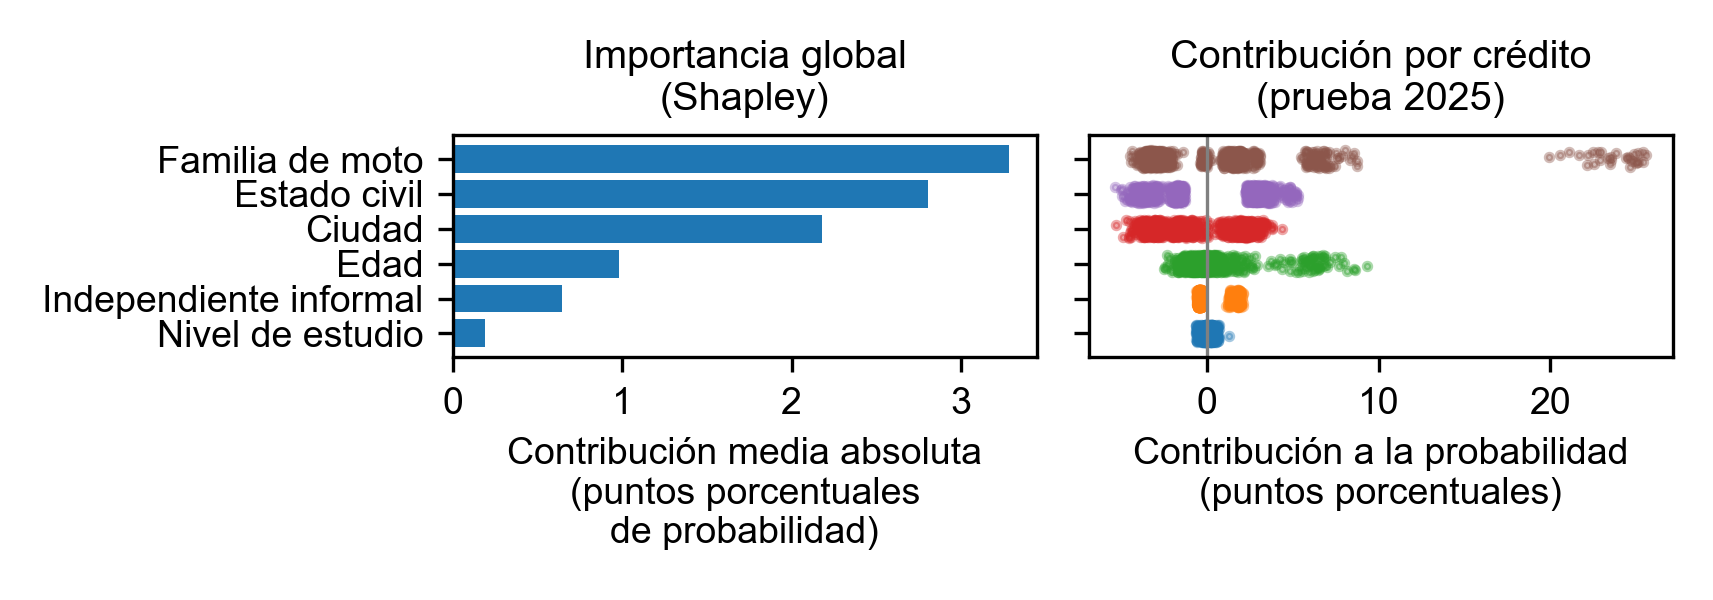

In [6]:
display(leer(D / "shap_global.csv"))
display(leer(D / "importancia_permutacion_2025.csv"))
display(Image(str(D / "shap_global.png")))

In [7]:
c = leer(D / "shap_por_categoria.csv")
c["shap_medio_pp"] = c["shap_medio"] * 100
# Por confidencialidad, cada familia de moto se muestra con su tipo de uso y una letra según su frecuencia (notebook 02)
import limpieza as L
etiqueta = L.etiquetas_familia(pd.read_parquet(RAIZ / "datos" / "base_protocolo.parquet", columns=["familia_moto", "tipo_uso_moto"]))
c["categoria"] = c["categoria"].where(c["variable"] != "familia_moto", c["categoria"].map(etiqueta))
c[["variable", "categoria", "creditos", "shap_medio_pp", "deterioro_observado"]]

,variable,categoria,creditos,shap_medio_pp,deterioro_observado
0,ciudad,QUIBDO,36,-3.5390,0.0278
1,ciudad,CALI,64,-3.5187,0.1094
2,ciudad,CUCUTA,78,-3.3287,0.0897
3,ciudad,VILLAVICENCIO,50,-2.8531,0.0600
4,ciudad,BELLO,36,-0.9344,0.1111
5,ciudad,OTRAS,483,-0.8816,0.0807
6,ciudad,MEDELLIN,194,2.0065,0.0773
7,ciudad,BUCARAMANGA,47,2.2191,0.1489
8,ciudad,BOGOTA,45,2.9020,0.2222
9,edad,18-25,171,-1.3066,0.1345


### 3.1 Tres créditos explicados

,caso,probabilidad,valor_base,variable,valor,contribucion
0,mayor riesgo,0.6041,0.2110,edad,58.0,0.0483
1,mayor riesgo,0.6041,0.2110,estado_civil,SOLTERO,0.0523
2,mayor riesgo,0.6041,0.2110,ciudad,ENVIGADO,0.0433
3,mayor riesgo,0.6041,0.2110,independiente_informal,0,-0.0045
4,mayor riesgo,0.6041,0.2110,nivel_estudio,POSTGRADO,-0.0023
5,mayor riesgo,0.6041,0.2110,familia_moto,Doble propósito C,0.2559
6,junto al corte del 20 %,0.2514,0.2110,edad,30.0,-0.0085
7,junto al corte del 20 %,0.2514,0.2110,estado_civil,SOLTERO,0.0315
8,junto al corte del 20 %,0.2514,0.2110,ciudad,MEDELLIN,0.0219
9,junto al corte del 20 %,0.2514,0.2110,independiente_informal,0,-0.0054


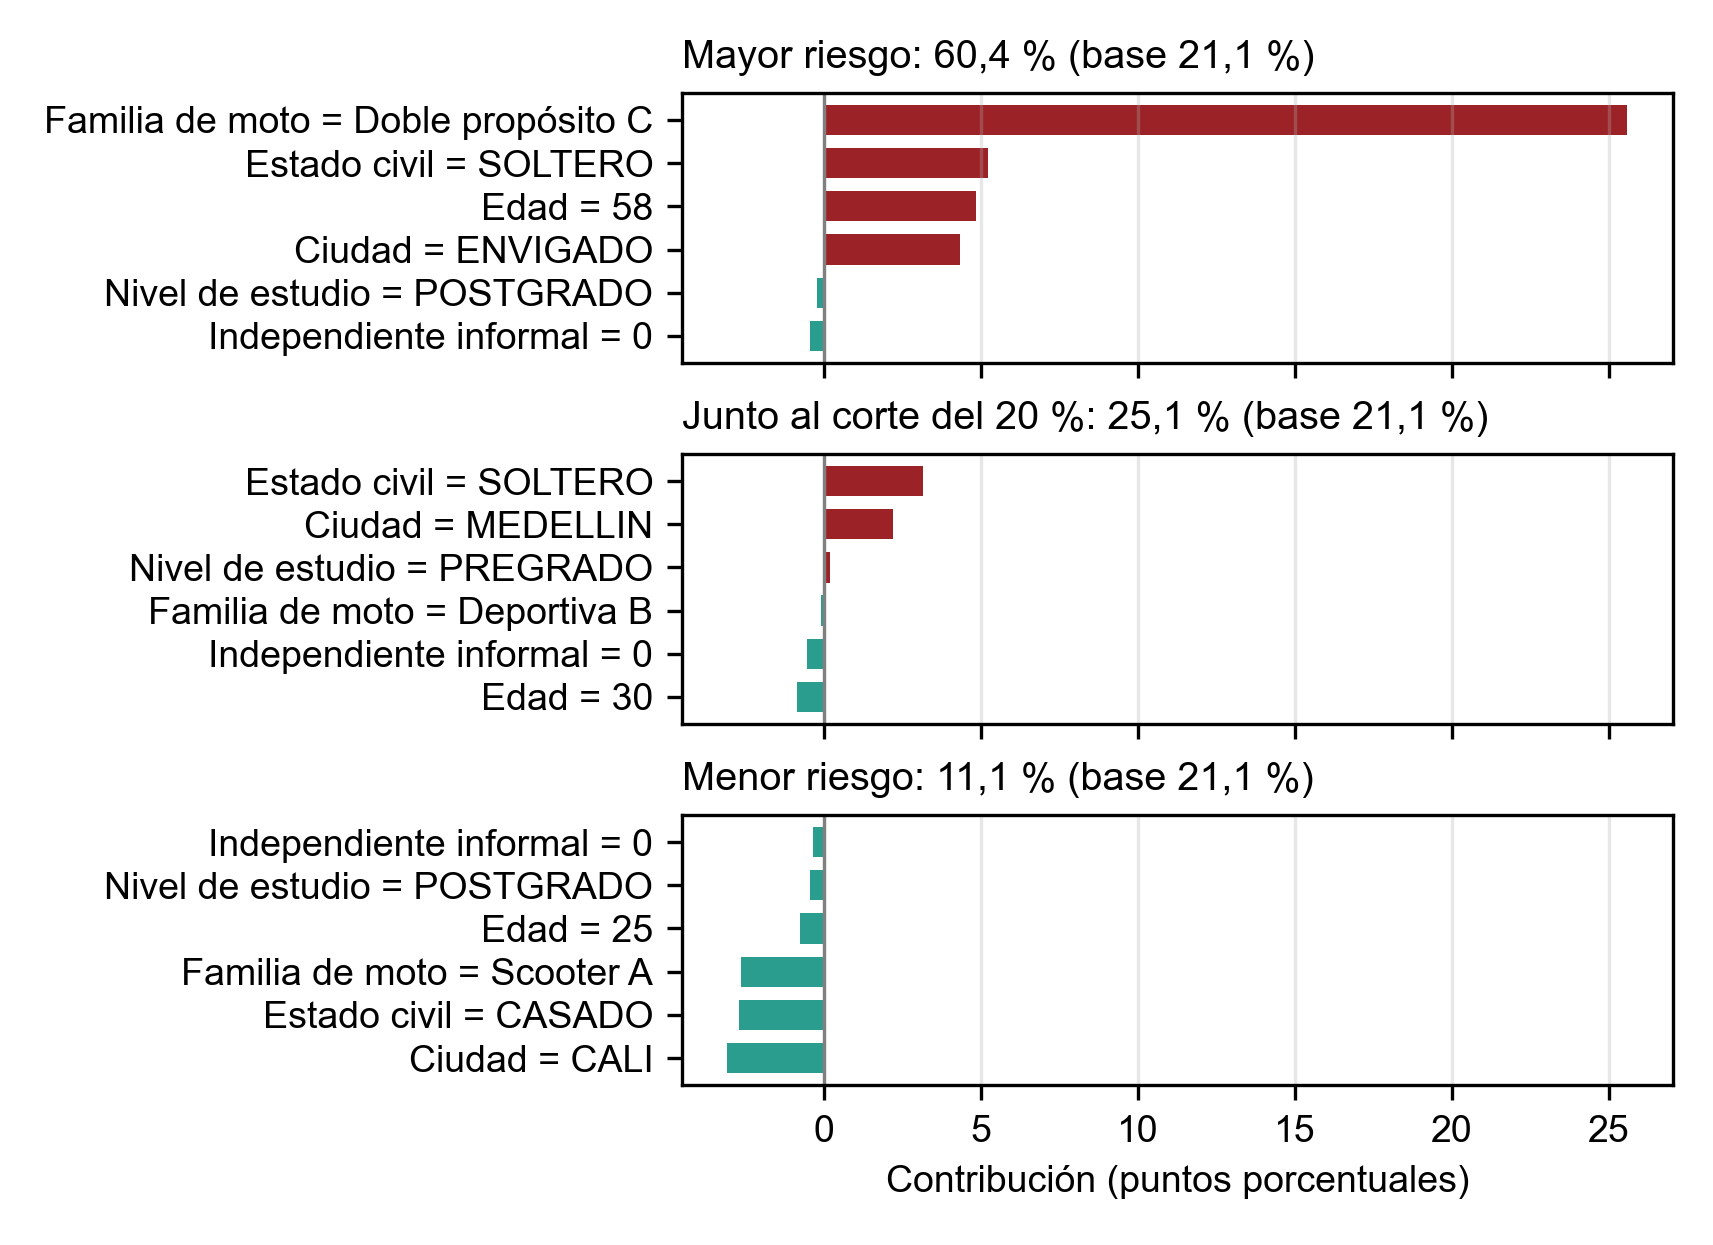

In [8]:
l = leer(D / "shap_local.csv")
l["valor"] = l["valor"].where(l["variable"] != "familia_moto", l["valor"].map(etiqueta))
display(l)
display(Image(str(D / "shap_local.png")))

**Lectura:**
- **Qué pesa más.** Del total de las contribuciones absolutas, la familia de moto aporta el 32,6 %, el estado civil el 27,8 %, la ciudad el 21,6 %, la edad el 9,7 %, el tipo de independiente el 6,4 % y el nivel de estudio el 1,9 %.
  - La permutación coincide en la primera: desordenar la familia de moto baja el AUC en 0,069.
  - Le siguen la ciudad (0,009), la edad (0,007), el tipo de independiente (0,006), el estado civil (0,005) y el nivel de estudio (0,003).
- **Hacia dónde mueve cada variable el riesgo estimado** (contribución media en 2025, en puntos de probabilidad):
  - **Familia de moto:** la Doble propósito C lo sube 23,6 puntos (29 créditos, 37,9 % de deterioro observado) y la Deportiva A lo sube 6,6. La Scooter A lo baja 3,2 (419 créditos, 5,0 % de deterioro).
  - **Estado civil:** casados −3,6 puntos y unión libre −1,7, frente a +3,0 en solteros.
  - **Edad:** los mayores de 51 años suben 3,1 puntos.
  - **Tipo de independiente:** los informales suben 1,7 puntos y los formales bajan 0,5.
  - **Ciudad:** Bogotá, Bucaramanga y Medellín suben 2,9, 2,2 y 2,0 puntos; Quibdó, Cali y Cúcuta bajan 3,5, 3,5 y 3,3.
- **Patrones aprendidos de 2023-2024.** El modelo refleja lo que vio en esos años, y no siempre coincide con 2025: Cali baja el riesgo estimado aunque en 2025 tuvo 10,9 % de deterioro, por encima del 9,0 % de la cartera. Las categorías con pocos créditos se deben leer con cautela.
- **El nivel de estudio es la variable que menos aporta** (1,9 %), coherente con que la eliminación hacia atrás lo retiró (notebook 03). Se mantiene porque C3 es la versión más simple entre las que no se distinguen de la mejor, según la regla registrada.
- **Los tres créditos:**
  - **Mayor riesgo (60,4 %, frente a un valor base de 21,1 %):** la familia Doble propósito C suma 25,6 puntos, ser soltero 5,2, la edad de 58 años 4,8 y la ciudad 4,3.
  - **Junto al corte del 20 % (25,1 %):** ser soltero suma 3,2 y la ciudad 2,2; la edad de 30 años resta 0,8.
  - **Menor riesgo (11,1 %):** la ciudad resta 3,1, estar casado 2,7 y la familia Scooter A 2,6.
  - El valor base corresponde al riesgo promedio de 2023-2024, por encima del de 2025. Por eso, en operación, el nivel se recalibra (notebook 07, sección 4).
- **Relación con la equidad:** las seis variables de C3 permiten reconstruir parcialmente el sexo y el estrato (notebook 07, sección 3.2). Por eso la auditoría de equidad acompaña al modelo.